# EDA: UCI 697 and Kaggle S4E6

This notebook audits the data before causal modeling. It checks structure, quality, treatment/outcome balance, leakage, overlap, and UCI versus Kaggle synthetic differences.

## 1. Environment and paths

This notebook runs in Google Colab, Jupyter, or VS Code. Kaggle CSV files can be placed in `data/kaggle_s4e6/`.

In [31]:
import os
import glob
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
ARTIFACT_DIR = ROOT / "artifacts" / "eda"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
print("Workspace:", ROOT)
print("Artifacts:", ARTIFACT_DIR)

Workspace: /content
Artifacts: /content/artifacts/eda


In [32]:
UCI_URL = "https://archive.ics.uci.edu/static/public/697/data.csv"
uci_path = DATA_DIR / "uci_697.csv"
def read_table(path_or_url):
    return pd.read_csv(path_or_url, sep=None, engine="python")
def normalize_columns(df):
    aliases = {"admissiongrade": "Admission grade", "ageatenrollment": "Age at enrollment", "scholarshipholder": "Scholarship holder", "target": "Target", "tuitionfeesuptodate": "Tuition fees up to date"}
    renamed = {}
    for col in df.columns:
        key = "".join(ch for ch in str(col).lower() if ch.isalnum())
        renamed[col] = aliases.get(key, str(col).strip())
    return df.rename(columns=renamed)
uci = normalize_columns(read_table(UCI_URL if not uci_path.exists() else uci_path))
if uci.shape[1] == 1:
    uci = normalize_columns(read_table(UCI_URL))
uci.to_csv(uci_path, index=False)
kaggle_candidates = [
    DATA_DIR / "kaggle_s4e6" / "train.csv",
    DATA_DIR / "train.csv",
    Path("/content/data/kaggle_s4e6/train.csv"),
    Path("/kaggle/input/playground-series-s4e6/train.csv"),
]
kaggle_train_path = next((p for p in kaggle_candidates if p.exists()), None)
kaggle = normalize_columns(read_table(kaggle_train_path)) if kaggle_train_path else None
required = ["Admission grade", "Scholarship holder", "Target", "Age at enrollment"]
missing = [col for col in required if col not in uci.columns]
if missing:
    raise ValueError(f"UCI is missing required columns: {missing}. Check the CSV delimiter.")
print(f"UCI shape: {uci.shape}")
print(f"Kaggle train: {kaggle_train_path if kaggle_train_path else 'not found - UCI-only mode' }")
display(uci.head())
if kaggle is not None:
    display(kaggle.head())

UCI shape: (4424, 37)
Kaggle train: not found - UCI-only mode


,﻿Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2. Load UCI 697 and detect Kaggle S4E6

UCI is loaded from the official URL. Kaggle is detected from common local paths and is skipped when no CSV is available.

In [33]:
def audit_dataset(df, name):
    result = pd.DataFrame({
        "dataset": [name],
        "rows": [len(df)],
        "columns": [df.shape[1]],
        "missing_cells": [int(df.isna().sum().sum())],
        "duplicate_rows": [int(df.duplicated().sum())],
        "duplicate_without_id": [int(df.drop(columns=["id"], errors="ignore").duplicated().sum())],
    })
    display(result)
    display(pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique(), "missing": df.isna().sum()}))
    if "Target" in df:
        display(df["Target"].value_counts(dropna=False).rename_axis("Target").to_frame("count").assign(rate=lambda x: x["count"] / len(df)))
audit_dataset(uci, "UCI 697")
if kaggle is not None:
    audit_dataset(kaggle, "Kaggle S4E6 train")

,dataset,rows,columns,missing_cells,duplicate_rows,duplicate_without_id
0,UCI 697,4424,37,0,0,0


,dtype,n_unique,missing
﻿Marital Status,int64,6,0
Application mode,int64,18,0
Application order,int64,8,0
Course,int64,17,0
Daytime/evening attendance,int64,2,0
Previous qualification,int64,17,0
Previous qualification (grade),float64,101,0
Nacionality,int64,21,0
Mother's qualification,int64,29,0
Father's qualification,int64,34,0


,count,rate
Target,,
Graduate,2209,0.499322
Dropout,1421,0.321203
Enrolled,794,0.179476


EDA notes

In [34]:
def treatment_audit(df, name):
    print(f"=== Profile: {name} ===")
    if "Scholarship holder" in df:
        print("Treatment distribution")
        display(df["Scholarship holder"].value_counts(normalize=False).rename("count").to_frame().assign(rate=lambda x: x["count"] / len(df)))
    if "Target" in df:
        print("Outcome distribution")
        display(df["Target"].value_counts(normalize=False).rename("count").to_frame().assign(rate=lambda x: x["count"] / len(df)))
    if {"Scholarship holder", "Target"}.issubset(df.columns):
        print("Treatment x outcome")
        display(pd.crosstab(df["Scholarship holder"], df["Target"], normalize="index").round(4))
        baseline = df[df["Target"].isin(["Dropout", "Graduate"])].copy()
        print("Binary causal cohort:", baseline.shape)
        if "Admission grade" in baseline:
            baseline["admission_bin"] = pd.qcut(baseline["Admission grade"], q=3, duplicates="drop")
            overlap = pd.crosstab(baseline["admission_bin"], baseline["Scholarship holder"], normalize="index")
            print("Treatment overlap by admission-grade tertile")
            display(overlap.round(4))
treatment_audit(uci, "UCI 697")
if kaggle is not None:
    treatment_audit(kaggle, "Kaggle S4E6 train")

=== Profile: UCI 697 ===
Treatment distribution


,count,rate
Scholarship holder,,
0,3325,0.751582
1,1099,0.248418


Outcome distribution


,count,rate
Target,,
Graduate,2209,0.499322
Dropout,1421,0.321203
Enrolled,794,0.179476


Treatment x outcome


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,0.3871,0.1997,0.4132
1,0.1219,0.1183,0.7598


Binary causal cohort: (3630, 37)
Treatment overlap by admission-grade tertile


Scholarship holder,0,1
admission_bin,,
"(94.999, 120.2]",0.7794,0.2206
"(120.2, 131.2]",0.6816,0.3184
"(131.2, 190.0]",0.7378,0.2622


## 3. Data audit

Inspect schema, dtypes, missing values, duplicates, identifiers, and target distribution.

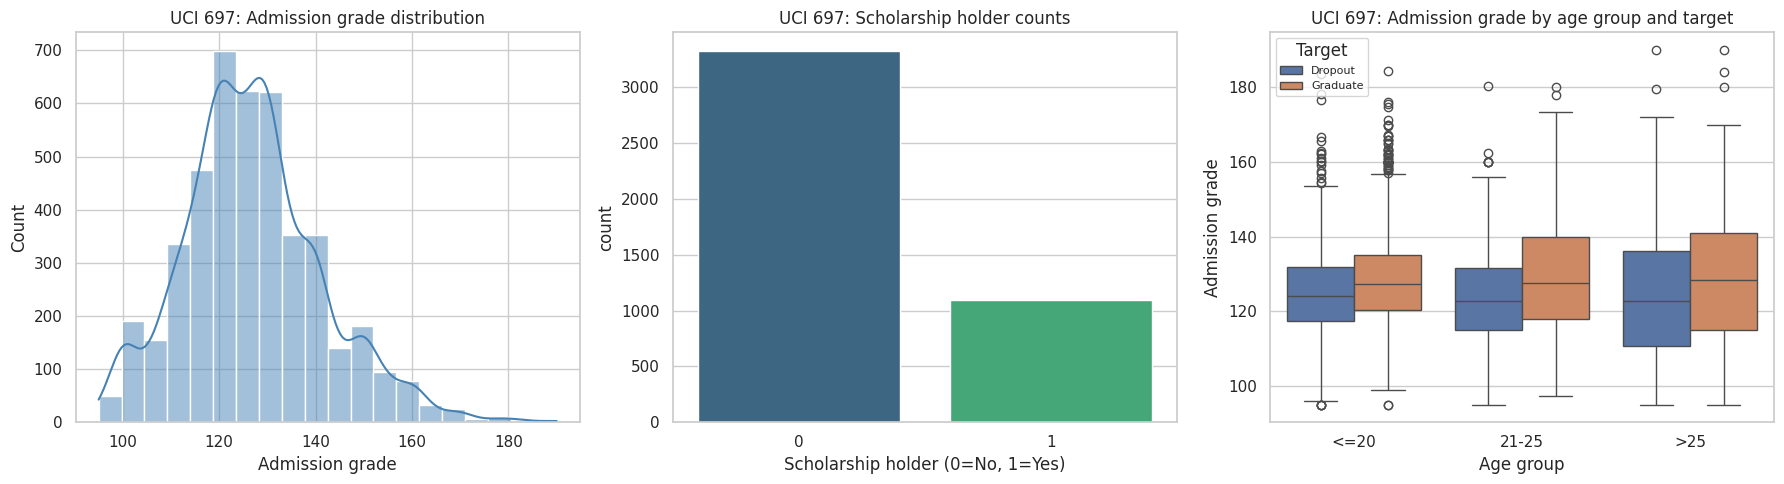

In [35]:
def plot_core_eda(df, name, prefix):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.histplot(df["Admission grade"], bins=20, kde=True, ax=axes[0], color="steelblue")
    axes[0].set_title(f"{name}: Admission grade distribution")
    axes[0].set_xlabel("Admission grade")
    sns.countplot(x="Scholarship holder", data=df, ax=axes[1], palette="viridis")
    axes[1].set_title(f"{name}: Scholarship holder counts")
    axes[1].set_xlabel("Scholarship holder (0=No, 1=Yes)")
    plot_df = df[df["Target"].isin(["Dropout", "Graduate"])].copy()
    plot_df["Age group"] = pd.cut(plot_df["Age at enrollment"], bins=[0, 20, 25, 100], labels=["<=20", "21-25", ">25"])
    sns.boxplot(x="Age group", y="Admission grade", hue="Target", data=plot_df, ax=axes[2])
    axes[2].set_title(f"{name}: Admission grade by age group and target")
    axes[2].legend(title="Target", fontsize=8)
    plt.tight_layout()
    fig.savefig(ARTIFACT_DIR / f"{prefix}_core_eda.png", dpi=160, bbox_inches="tight")
    plt.show()
plot_core_eda(uci, "UCI 697", "uci")
if kaggle is not None:
    plot_core_eda(kaggle, "Kaggle S4E6", "kaggle")

EDA notes

In [36]:
def profile_dataset(df, name):
    cols = [c for c in ["Admission grade", "Age at enrollment", "Previous qualification (grade)", "Debtor", "Tuition fees up to date", "Target"] if c in df.columns]
    if "Scholarship holder" not in df.columns:
        return
    print(f"=== Profile: {name} ===")
    profile = df.groupby("Scholarship holder").agg(
        so_luong=("Scholarship holder", "size"),
        admission_grade_tb=("Admission grade", "mean"),
        tuoi_tb=("Age at enrollment", "mean"),
        ty_le_no_hoc_phi=("Debtor", "mean"),
        ty_le_dong_hoc_phi_dung_han=("Tuition fees up to date", "mean"),
    ).round(3)
    display(profile)
    if "Target" in df.columns:
        display(pd.crosstab(df["Scholarship holder"], df["Target"], normalize="index").round(3))
profile_dataset(uci, "UCI 697")
if kaggle is not None:
    profile_dataset(kaggle, "Kaggle S4E6 train")

=== Profile: UCI 697 ===


,so_luong,admission_grade_tb,tuoi_tb,ty_le_no_hoc_phi,ty_le_dong_hoc_phi_dung_han
Scholarship holder,,,,,
0,3325,126.821,24.094,0.126,0.855
1,1099,127.454,20.759,0.076,0.958


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,0.387,0.200,0.413
1,0.122,0.118,0.760


## 4. Treatment, outcome, and overlap

Treatment is Scholarship holder. The binary causal cohort keeps Dropout and Graduate and excludes Enrolled.

=== Profile: UCI 697 ===


,mutual_information
Tuition fees up to date,0.1010
Scholarship holder,0.0663
Age at enrollment,0.0607
Application mode,0.0588
Course,0.0520
Previous qualification (grade),0.0435
Admission grade,0.0333
Gender,0.0307
Mother's occupation,0.0300
Previous qualification,0.0263


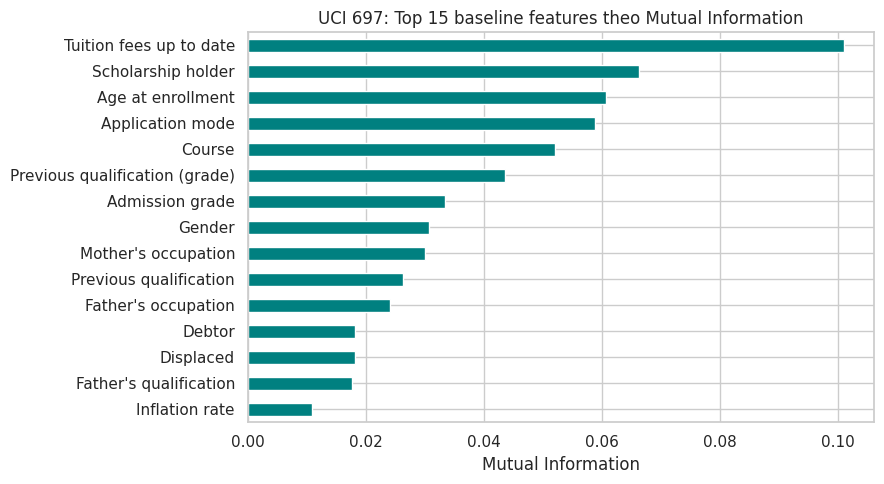

In [37]:
def mutual_information_report(df, name, prefix):
    work = df[df["Target"].isin(["Dropout", "Graduate"])].copy()
    y = (work["Target"] == "Graduate").astype(int)
    drop_cols = ["Target", "id"]
    baseline_cols = [c for c in work.columns if "Curricular units" not in c and c not in drop_cols]
    X = work[baseline_cols].copy()
    cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
    if cat_cols:
        X[cat_cols] = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(X[cat_cols].astype(str))
    X = X.fillna(X.median(numeric_only=True)).fillna(0)
    discrete_mask = np.array([c in cat_cols for c in X.columns])
    scores = mutual_info_classif(X, y, discrete_features=discrete_mask, random_state=RANDOM_STATE)
    mi = pd.Series(scores, index=X.columns).sort_values(ascending=False)
    print(f"=== Profile: {name} ===")
    display(mi.head(15).round(4).to_frame("mutual_information"))
    fig, ax = plt.subplots(figsize=(9, 5))
    mi.head(15).sort_values().plot(kind="barh", ax=ax, color="teal")
    ax.set_title(f"{name}: Top 15 baseline features theo Mutual Information")
    ax.set_xlabel("Mutual Information")
    plt.tight_layout()
    fig.savefig(ARTIFACT_DIR / f"{prefix}_mutual_information.png", dpi=160, bbox_inches="tight")
    plt.show()
    return mi
uci_mi = mutual_information_report(uci, "UCI 697", "uci")
if kaggle is not None:
    kaggle_mi = mutual_information_report(kaggle, "Kaggle S4E6 train", "kaggle")

EDA notes

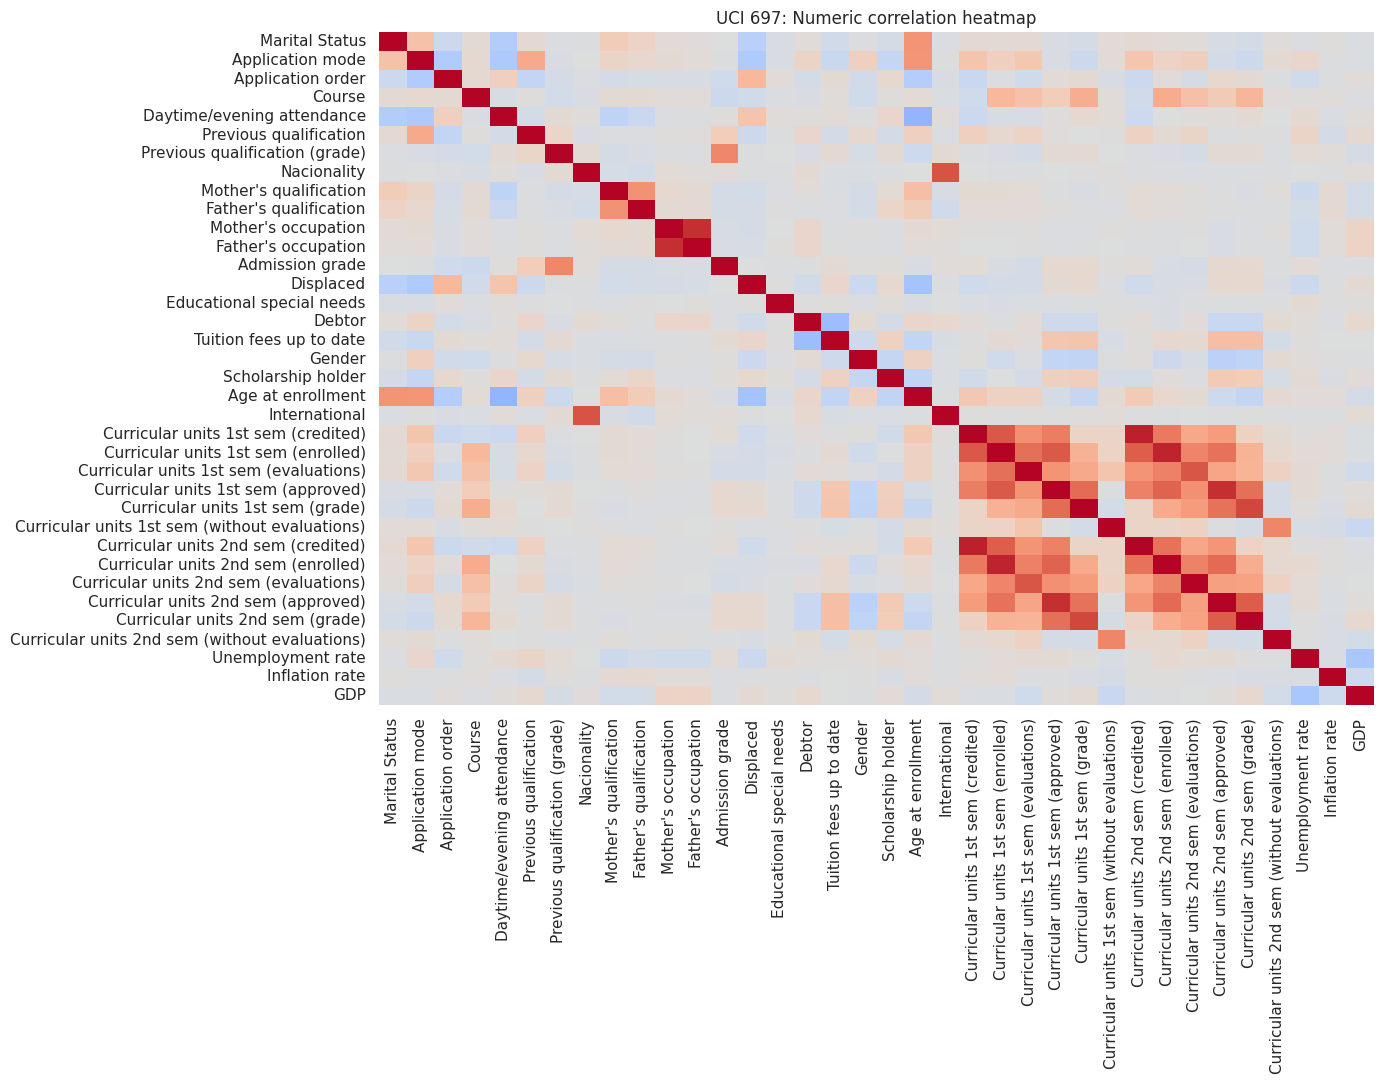

Top correlated pairs


,,abs_correlation
Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.944811
Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.942627
Mother's occupation,Father's occupation,0.910472
Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.904002
Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.837170
Nacionality,International,0.790935
Curricular units 1st sem (evaluations),Curricular units 2nd sem (evaluations),0.778863
Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),0.774344
Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),0.769083
Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),0.760804


In [38]:
def correlation_report(df, name, prefix):
    numeric = df.select_dtypes(include=np.number).copy()
    numeric = numeric.drop(columns=["id"], errors="ignore")
    corr = numeric.corr()
    fig, ax = plt.subplots(figsize=(14, 11))
    sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, cbar=False)
    ax.set_title(f"{name}: Numeric correlation heatmap")
    plt.tight_layout()
    fig.savefig(ARTIFACT_DIR / f"{prefix}_correlation_heatmap.png", dpi=160, bbox_inches="tight")
    plt.show()
    pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().abs().sort_values(ascending=False)
    print("Top correlated pairs")
    display(pairs.head(15).to_frame("abs_correlation"))
correlation_report(uci, "UCI 697", "uci")
if kaggle is not None:
    correlation_report(kaggle, "Kaggle S4E6 train", "kaggle")

## 5. Main EDA plots

The plots adapt the reference G3/studytime/higher analysis to UCI 697: admission-grade distribution, treatment counts, and outcome by age group.

In [39]:
if kaggle is None:
    print("Kaggle train.csv not found; comparison skipped.")
else:
    common_numeric = sorted(set(uci.select_dtypes(include=np.number).columns) & set(kaggle.select_dtypes(include=np.number).columns) - {"id"})
    comparison = pd.DataFrame({
        "uci_mean": uci[common_numeric].mean(),
        "kaggle_mean": kaggle[common_numeric].mean(),
        "uci_std": uci[common_numeric].std(),
        "kaggle_std": kaggle[common_numeric].std(),
    })
    comparison["mean_difference"] = comparison["kaggle_mean"] - comparison["uci_mean"]
    display(comparison.sort_values("mean_difference", key=abs, ascending=False).head(20).round(4))
    comparison.to_csv(ARTIFACT_DIR / "uci_kaggle_numeric_comparison.csv")
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    sns.histplot(data=uci, x="Admission grade", stat="density", bins=25, color="steelblue", alpha=.45, label="UCI", ax=axes[0])
    sns.histplot(data=kaggle, x="Admission grade", stat="density", bins=25, color="darkorange", alpha=.45, label="Kaggle", ax=axes[0])
    axes[0].legend()
    axes[0].set_title("Admission grade: UCI vs Kaggle")
    target_rates = pd.DataFrame({
        "UCI": uci["Target"].value_counts(normalize=True),
        "Kaggle": kaggle["Target"].value_counts(normalize=True),
    })
    target_rates.plot(kind="bar", ax=axes[1], color=["steelblue", "darkorange"])
    axes[1].set_title("Target distribution: UCI vs Kaggle")
    axes[1].set_ylabel("Rate")
    plt.tight_layout()
    fig.savefig(ARTIFACT_DIR / "uci_kaggle_comparison.png", dpi=160, bbox_inches="tight")
    plt.show()

Kaggle train.csv not found; comparison skipped.


EDA notes

## 6. Phan tich chuyen sau: chat luong, thoi gian va causal readiness

Kiem tra phan bo bien, imbalance, outlier, duplicate, leakage, overlap va association theo tang baseline. Ket qua mo ta khong duoc dien giai thanh causal effect.

=== Advanced EDA: UCI 697 ===
Numeric columns: 36 | Categorical columns: 1
Rows: 4424 | Missing cells: 0


,status
0,No missing values


,n_unique,unique_rate
Daytime/evening attendance,2,0.000452
Displaced,2,0.000452
Debtor,2,0.000452
Educational special needs,2,0.000452
International,2,0.000452
Scholarship holder,2,0.000452
Gender,2,0.000452
Tuition fees up to date,2,0.000452
Target,3,0.000678
﻿Marital Status,6,0.001356


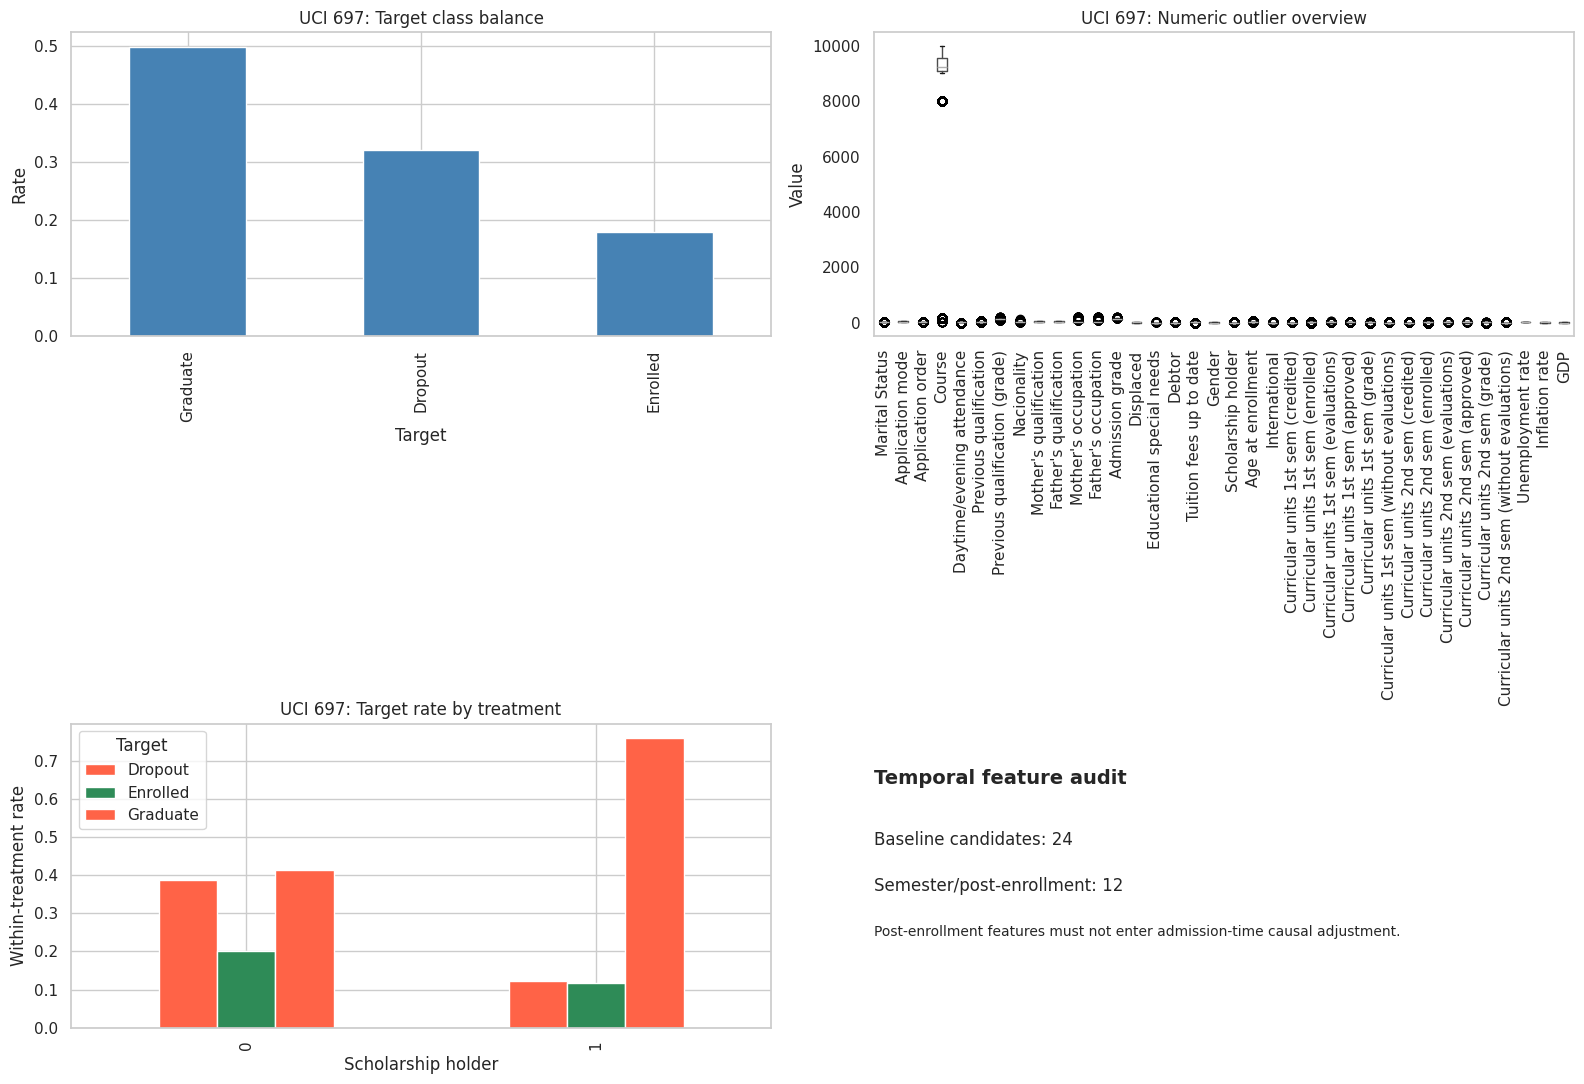

Stratified treatment overlap


,admission_bin,age_bin,count,mean,min,max
0,"(94.999, 118.0]",<=20,424,0.285377,0,1
1,"(94.999, 118.0]",21-25,191,0.225131,0,1
2,"(94.999, 118.0]",>25,297,0.104377,0,1
3,"(118.0, 126.5]",<=20,594,0.390572,0,1
4,"(118.0, 126.5]",21-25,144,0.250000,0,1
5,"(118.0, 126.5]",>25,172,0.104651,0,1
6,"(126.5, 135.1]",<=20,583,0.365352,0,1
7,"(126.5, 135.1]",21-25,145,0.193103,0,1
8,"(126.5, 135.1]",>25,173,0.127168,0,1
9,"(135.1, 190.0]",<=20,479,0.352818,0,1


,admission_bin,age_bin,observed_rate_difference
0,"(94.999, 118.0]",<=20,0.301776
1,"(94.999, 118.0]",21-25,0.352294
2,"(94.999, 118.0]",>25,0.475018
3,"(118.0, 126.5]",<=20,0.248262
4,"(118.0, 126.5]",21-25,0.416667
5,"(118.0, 126.5]",>25,0.380952
6,"(126.5, 135.1]",<=20,0.208235
7,"(126.5, 135.1]",21-25,0.465507
8,"(126.5, 135.1]",>25,0.325105
9,"(135.1, 190.0]",<=20,0.145638


Potentially redundant numeric pairs


,,absolute_correlation
Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.944811
Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.942627
Mother's occupation,Father's occupation,0.910472
Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.904002
Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.837170
Nacionality,International,0.790935
Curricular units 1st sem (evaluations),Curricular units 2nd sem (evaluations),0.778863
Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),0.774344
Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),0.769083
Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),0.760804


In [40]:
def advanced_eda(df, name, prefix):
    print(f"=== Advanced EDA: {name} ===")
    numeric = df.select_dtypes(include=np.number).drop(columns=["id"], errors="ignore")
    categorical = df.select_dtypes(exclude=np.number)
    print("Numeric columns:", numeric.shape[1], "| Categorical columns:", categorical.shape[1])
    print("Rows:", len(df), "| Missing cells:", int(df.isna().sum().sum()))
    missing = df.isna().sum().sort_values(ascending=False)
    display(missing[missing.gt(0)].to_frame("missing_count") if missing.gt(0).any() else pd.DataFrame({"status": ["No missing values"]}))
    unique_summary = pd.DataFrame({"n_unique": df.nunique(), "unique_rate": df.nunique() / len(df)}).sort_values("n_unique")
    display(unique_summary.head(15))
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    if "Target" in df:
        df["Target"].value_counts(normalize=True).plot.bar(ax=axes[0, 0], color="steelblue")
        axes[0, 0].set_title(f"{name}: Target class balance")
        axes[0, 0].set_ylabel("Rate")
    numeric.boxplot(ax=axes[0, 1], rot=90, grid=False)
    axes[0, 1].set_title(f"{name}: Numeric outlier overview")
    axes[0, 1].set_ylabel("Value")
    if {"Scholarship holder", "Target"}.issubset(df.columns):
        pd.crosstab(df["Scholarship holder"], df["Target"], normalize="index").plot.bar(ax=axes[1, 0], color=["tomato", "seagreen"])
        axes[1, 0].set_title(f"{name}: Target rate by treatment")
        axes[1, 0].set_ylabel("Within-treatment rate")
        axes[1, 0].legend(title="Target")
    baseline_cols = [c for c in df.columns if "Curricular units" not in c and c not in ["Target", "id"]]
    post_enrollment_cols = [c for c in df.columns if "Curricular units" in c]
    axes[1, 1].axis("off")
    axes[1, 1].text(0, 0.8, "Temporal feature audit", fontsize=14, weight="bold")
    axes[1, 1].text(0, 0.6, f"Baseline candidates: {len(baseline_cols)}", fontsize=12)
    axes[1, 1].text(0, 0.45, f"Semester/post-enrollment: {len(post_enrollment_cols)}", fontsize=12)
    axes[1, 1].text(0, 0.3, "Post-enrollment features must not enter admission-time causal adjustment.", fontsize=10, wrap=True)
    plt.tight_layout()
    fig.savefig(ARTIFACT_DIR / f"{prefix}_advanced_quality.png", dpi=160, bbox_inches="tight")
    plt.show()
    if {"Scholarship holder", "Target", "Admission grade"}.issubset(df.columns):
        work = df[df["Target"].isin(["Dropout", "Graduate"])].copy()
        work["admission_bin"] = pd.qcut(work["Admission grade"], q=4, duplicates="drop")
        work["age_bin"] = pd.cut(work["Age at enrollment"], bins=[0, 20, 25, 100], labels=["<=20", "21-25", ">25"])
        overlap = work.groupby(["admission_bin", "age_bin"], observed=True)["Scholarship holder"].agg(["count", "mean", "min", "max"]).reset_index()
        print("Stratified treatment overlap")
        display(overlap)
        effect = work.groupby(["admission_bin", "age_bin"], observed=True).apply(lambda g: g.groupby("Scholarship holder")["Target"].apply(lambda s: (s == "Graduate").mean()).diff().iloc[-1] if g["Scholarship holder"].nunique() == 2 else np.nan, include_groups=False).rename("observed_rate_difference").reset_index()
        display(effect)
        effect.to_csv(ARTIFACT_DIR / f"{prefix}_stratified_observed_difference.csv", index=False)
    high_corr = numeric.corr().where(np.triu(np.ones(numeric.corr().shape), k=1).astype(bool)).stack().abs().sort_values(ascending=False)
    print("Potentially redundant numeric pairs")
    display(high_corr.head(20).to_frame("absolute_correlation"))

advanced_eda(uci, "UCI 697", "uci")
if kaggle is not None:
    advanced_eda(kaggle, "Kaggle S4E6", "kaggle")